# Projet 10 – Prédire l'attrition des employés (ESN)
## Étape 2 : Préparation des données pour la modélisation

**Objectif :** obtenir un DataFrame `X` (features) et une Series `y` (cible `a_quitte_l_entreprise`) utilisables directement dans un `fit()` de scikit-learn.

**Plan du notebook**
1. Chargement du fichier central
2. Séparation `X` / `y`
3. Étude des corrélations (Pearson, pairplot, Spearman) et suppression des features redondantes
4. Encodage des variables qualitatives
5. Contrôles finaux et fonctions réutilisables (`preparation.py`)

---
## 1. Chargement des données
Le fichier central de l'étape 1 est reconstruit par la fonction `charger_donnees()` (jointure des 3 fichiers + nettoyage), définie dans `preparation.py`.

In [16]:
import pandas as pd
from preparation import charger_donnees, preparer_donnees

df = charger_donnees()
print(df.shape)

(1470, 29)


---
## 2. Séparation des données
- **`y`** : la cible `a_quitte_l_entreprise` (0 = resté, 1 = parti).
- **`X`** : toutes les autres colonnes, sauf `id_employee`, qui n'est qu'un identifiant sans valeur explicative.

In [17]:
y = df["a_quitte_l_entreprise"]
X = df.drop(columns=["a_quitte_l_entreprise", "id_employee"])

print(X.shape, y.shape)
print(y.value_counts())

(1470, 27) (1470,)
a_quitte_l_entreprise
0    1233
1     237
Name: count, dtype: int64


### Types de données
On repère quelles colonnes sont numériques (utilisables dans une corrélation) et lesquelles sont du texte (à encoder).

In [18]:
X.dtypes

age                                            int64
genre                                            str
revenu_mensuel                                 int64
statut_marital                                   str
departement                                      str
poste                                            str
nombre_experiences_precedentes                 int64
annee_experience_totale                        int64
annees_dans_l_entreprise                       int64
annees_dans_le_poste_actuel                    int64
satisfaction_employee_environnement            int64
note_evaluation_precedente                     int64
niveau_hierarchique_poste                      int64
satisfaction_employee_nature_travail           int64
satisfaction_employee_equipe                   int64
satisfaction_employee_equilibre_pro_perso      int64
note_evaluation_actuelle                       int64
heure_supplementaires                          int64
augmentation_salaire_precedente              f

---
## 3. Corrélations entre features
### 3.1 Corrélation de Pearson
Elle mesure les relations **linéaires** entre colonnes **numériques** uniquement (le texte est exclu). On cherche les paires très corrélées (> 0,8 en valeur absolue), car elles apportent la même information.

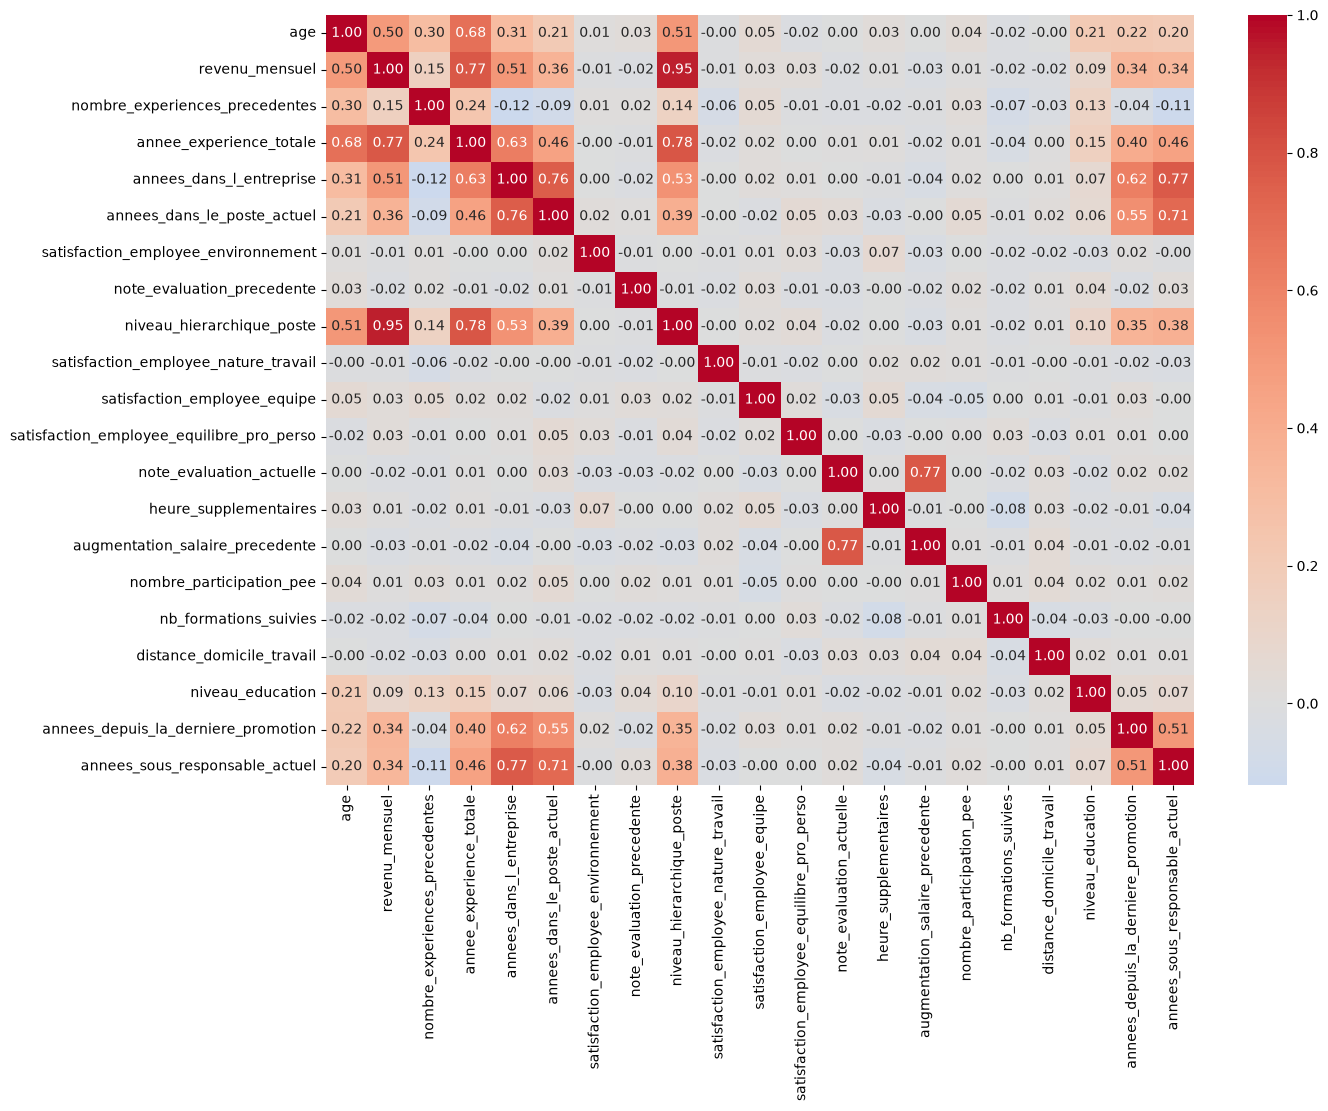

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

X_num = X.select_dtypes(include="number")

plt.figure(figsize=(14, 10))
sns.heatmap(X_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Conclusion :** une seule paire très forte, `revenu_mensuel` ↔ `niveau_hierarchique_poste` (0,95). Plusieurs paires restent élevées sans atteindre 0,8 (par ex. `annee_experience_totale` ↔ `revenu_mensuel` : 0,77).

### 3.2 Suppression de `niveau_hierarchique_poste`
Corrélation de **0,95** avec `revenu_mensuel`. On conserve `revenu_mensuel`, plus précis (valeur continue) et déjà identifié comme lié au départ.

In [20]:
X = X.drop(columns=["niveau_hierarchique_poste"])
X_num = X.select_dtypes(include="number")
print(X.shape)

(1470, 26)


### 3.3 Pairplot
Il permet de visualiser les relations entre colonnes, y compris **non linéaires**, que Pearson ne détecte pas. Sur 5 colonnes représentatives, points colorés selon le départ (bleu = resté, orange = parti).

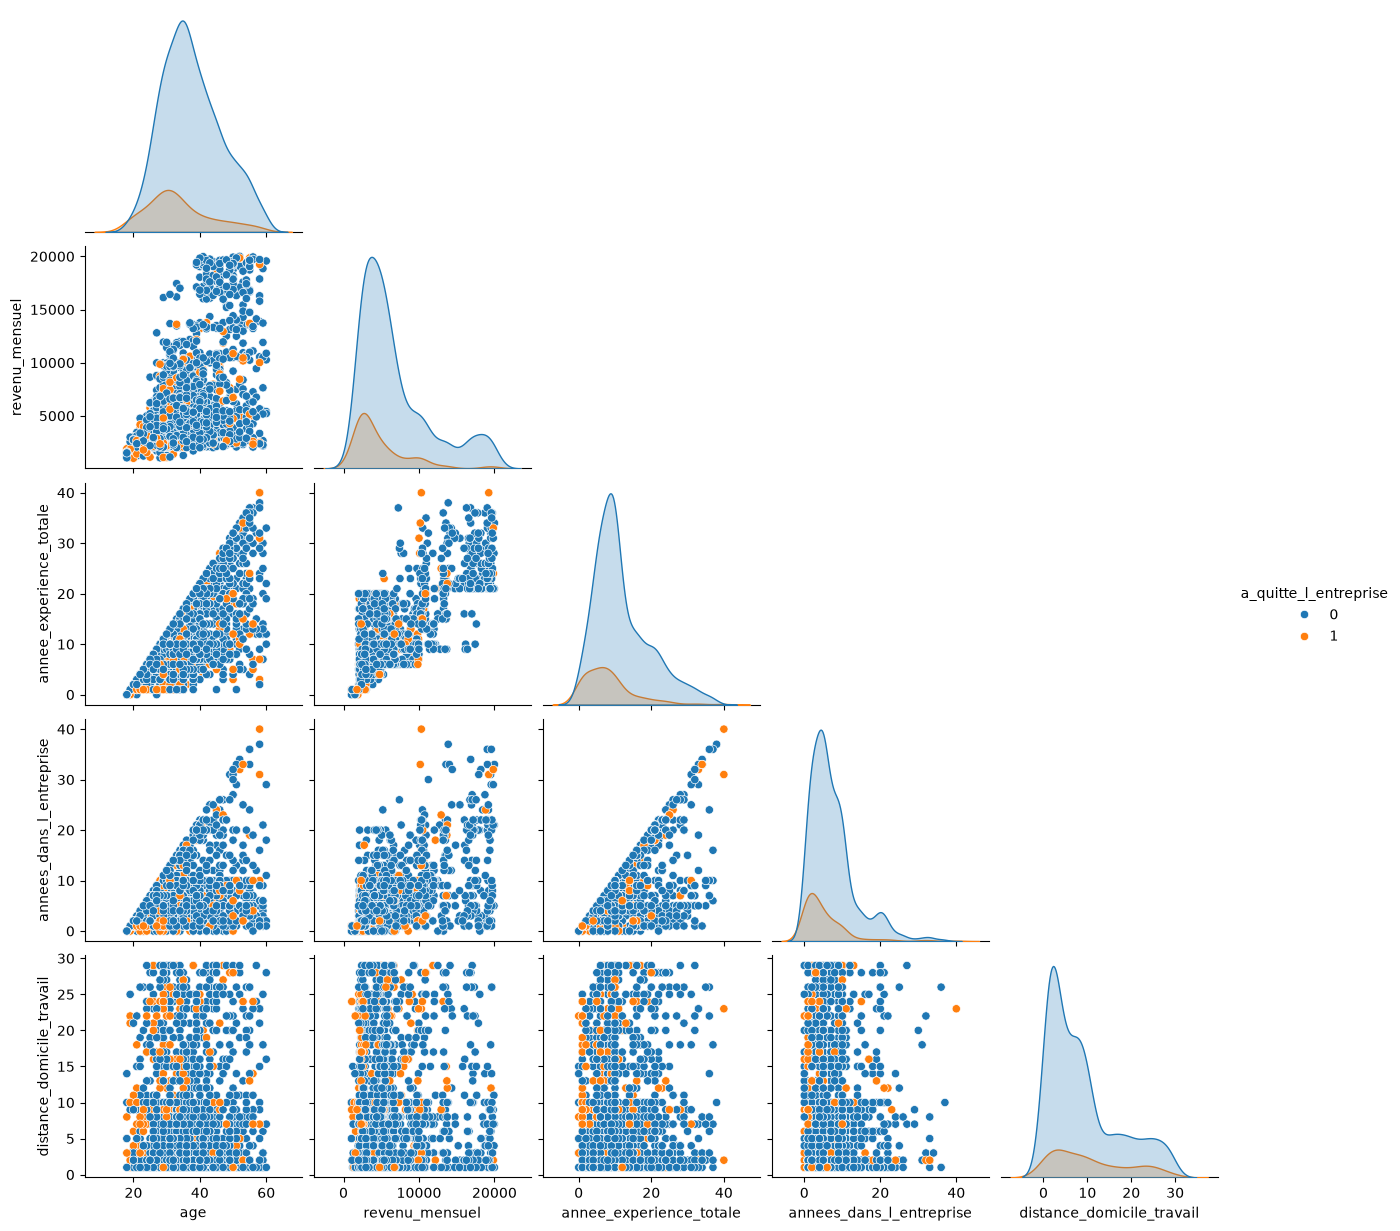

In [21]:
cols = ["age", "revenu_mensuel", "annee_experience_totale",
        "annees_dans_l_entreprise", "distance_domicile_travail"]

sns.pairplot(df[cols + ["a_quitte_l_entreprise"]],
             hue="a_quitte_l_entreprise", corner=True)
plt.show()

**Conclusion :**
- `age` × `annee_experience_totale` (et `annees_dans_l_entreprise`) forment un **triangle** : on ne peut pas avoir plus d'années d'expérience que d'années de vie active. Le lien est logique.
- `distance_domicile_travail` ne forme qu'un nuage sans structure : aucun lien avec les autres colonnes.
- Les partis (orange) se situent plutôt parmi les jeunes, les faibles revenus et la faible ancienneté, ce qui confirme l'étape 1.
- Pas de relation courbe particulière : Pearson reste une bonne référence.

### 3.4 Corrélation de Spearman
Elle repère aussi les liens qui montent ou descendent sans être des droites parfaites (corrélation de rang).

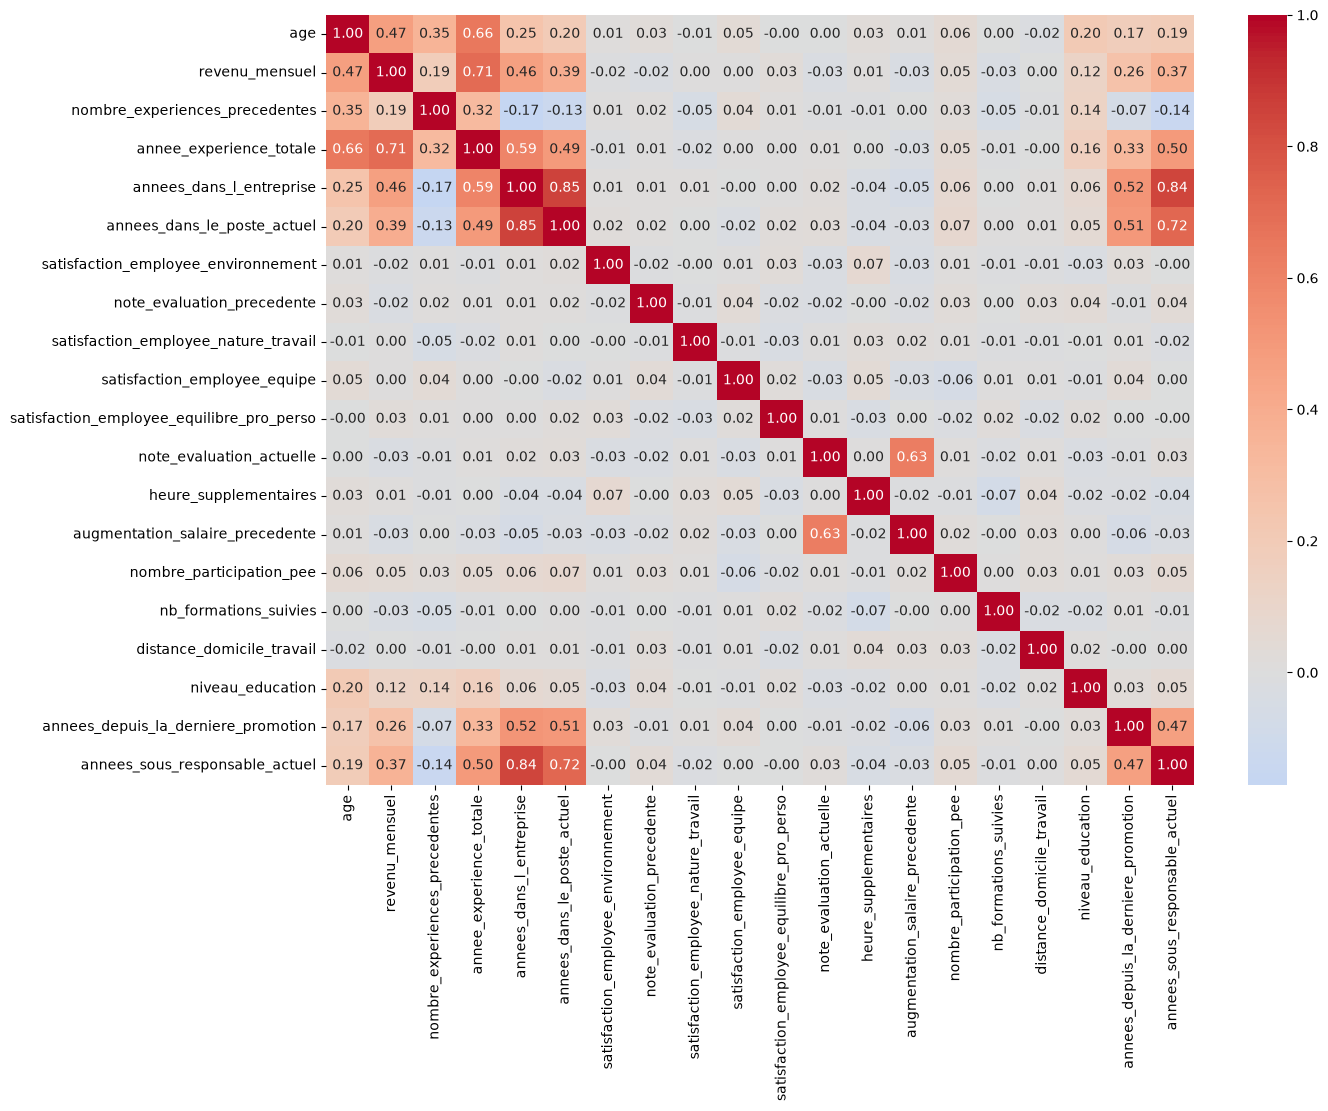

In [22]:
plt.figure(figsize=(14, 10))
sns.heatmap(X_num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Conclusion :** deux paires dépassent 0,8 : `annees_dans_l_entreprise` ↔ `annees_dans_le_poste_actuel` (0,85) et ↔ `annees_sous_responsable_actuel` (0,84).

### 3.5 Suppression de `annees_dans_le_poste_actuel` et `annees_sous_responsable_actuel`
Spearman révèle une forte redondance avec `annees_dans_l_entreprise` (**0,85** et **0,84**) : ces trois colonnes mesurent des durées qui évoluent ensemble. On garde la plus générale, `annees_dans_l_entreprise`.

In [23]:
X = X.drop(columns=["annees_dans_le_poste_actuel", "annees_sous_responsable_actuel"])
print(X.shape)

X_num = X.select_dtypes(include="number")

(1470, 24)


### 3.6 Vérification après suppression

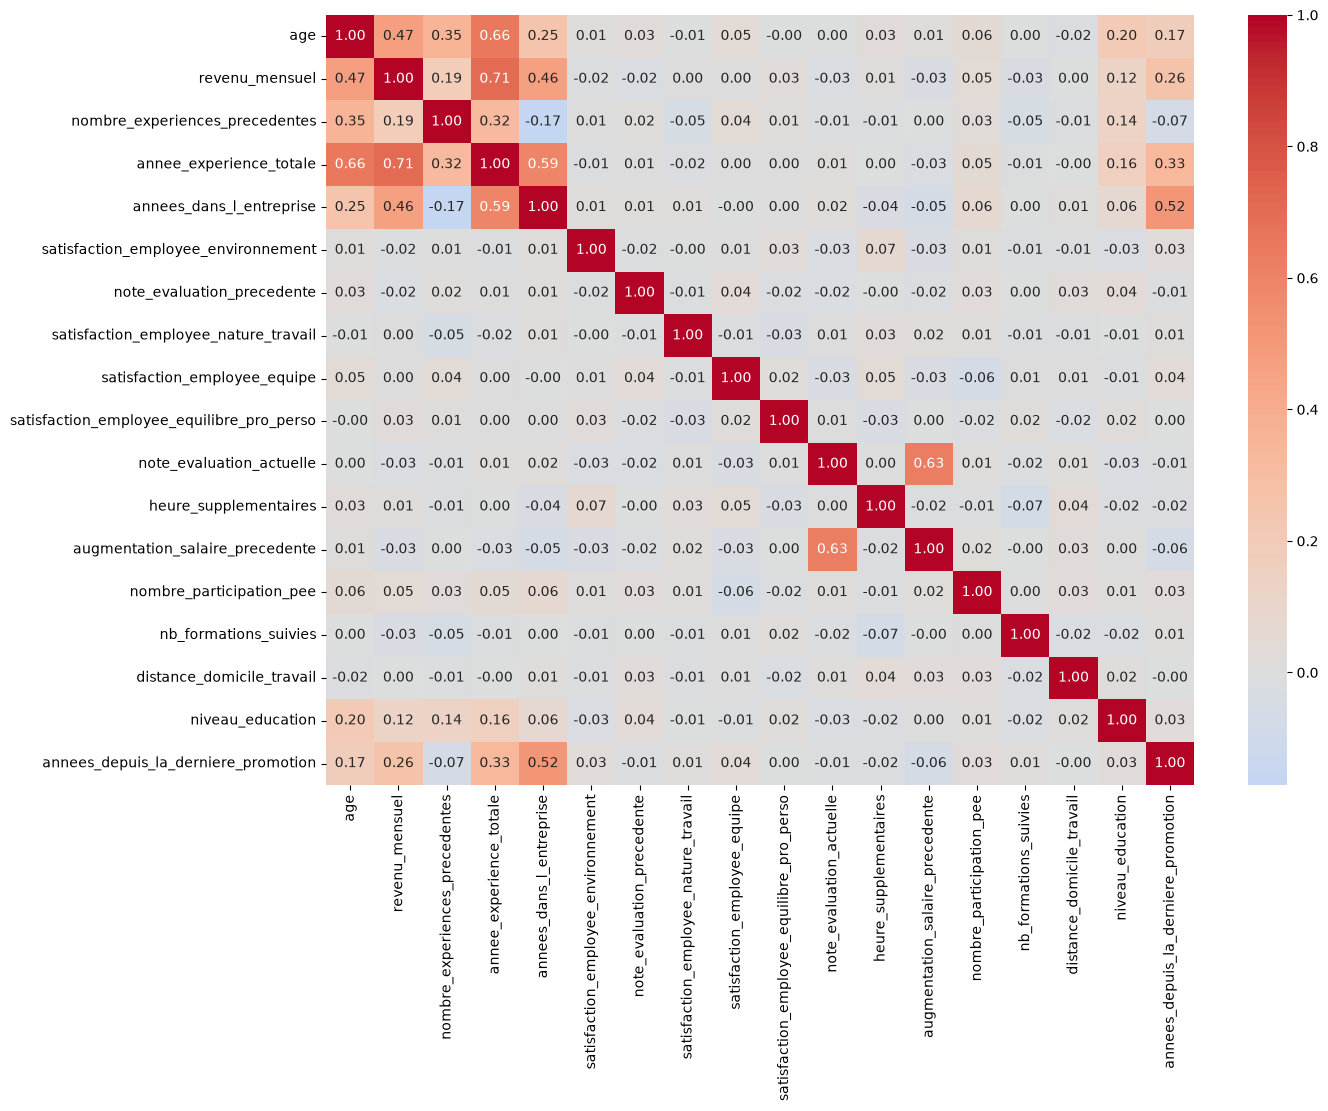

In [24]:
plt.figure(figsize=(14, 10))
sns.heatmap(X_num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Conclusion :** plus aucune paire au-dessus de 0,8. La plus forte est `revenu_mensuel` ↔ `annee_experience_totale` (0,71). `X` compte maintenant 24 colonnes dont 18 numériques et 6 texte.

---
## 4. Encodage des variables qualitatives
Les modèles ne lisent que des nombres. Le choix de la méthode dépend du **sens métier** :
- valeurs avec un **ordre naturel** → encodage ordinal ;
- simples catégories **sans ordre** → One Hot Encoding.

On liste d'abord les 6 colonnes texte et leurs valeurs.

In [25]:
X.select_dtypes(exclude="number").columns

Index(['genre', 'statut_marital', 'departement', 'poste', 'domaine_etude',
       'frequence_deplacement'],
      dtype='str')

In [26]:
for col in X.select_dtypes(exclude="number").columns:
    print(col, X[col].unique())

genre <StringArray>
['F', 'M']
Length: 2, dtype: str
statut_marital <StringArray>
['Célibataire', 'Marié(e)', 'Divorcé(e)']
Length: 3, dtype: str
departement <StringArray>
['Commercial', 'Consulting', 'Ressources Humaines']
Length: 3, dtype: str
poste <StringArray>
[       'Cadre Commercial',  'Assistant de Direction',
              'Consultant',               'Tech Lead',
                 'Manager',          'Senior Manager',
 'Représentant Commercial',     'Directeur Technique',
     'Ressources Humaines']
Length: 9, dtype: str
domaine_etude <StringArray>
[          'Infra & Cloud',                   'Autre',
 'Transformation Digitale',               'Marketing',
         'Entrepreunariat',     'Ressources Humaines']
Length: 6, dtype: str
frequence_deplacement <StringArray>
['Occasionnel', 'Frequent', 'Aucun']
Length: 3, dtype: str


**Colonnes texte :** `genre` (2 valeurs), `statut_marital` (3), `departement` (3), `poste` (9), `domaine_etude` (6), `frequence_deplacement` (3).

### 4.1 Encodage ordinal : `frequence_deplacement`
Seule colonne avec un ordre naturel : Aucun (0) < Occasionnel (1) < Frequent (2).

In [27]:
ordre = {"Aucun": 0, "Occasionnel": 1, "Frequent": 2}
X["frequence_deplacement"] = X["frequence_deplacement"].map(ordre)

print(X["frequence_deplacement"].value_counts())

frequence_deplacement
1    1043
2     277
0     150
Name: count, dtype: int64


### 4.2 One Hot Encoding : `genre`, `statut_marital`, `departement`, `poste`, `domaine_etude`
Ces colonnes n'ont pas d'ordre (un encodage 0/1/2 imposerait un ordre artificiel). `drop_first=True` retire une catégorie par colonne (catégorie de référence) pour éviter les colonnes redondantes, problématiques pour les modèles linéaires.

In [28]:
cols_onehot = ["genre", "statut_marital", "departement", "poste", "domaine_etude"]

X = pd.get_dummies(X, columns=cols_onehot, drop_first=True, dtype=int)

print(X.shape)
X.dtypes

(1470, 37)


age                                            int64
revenu_mensuel                                 int64
nombre_experiences_precedentes                 int64
annee_experience_totale                        int64
annees_dans_l_entreprise                       int64
satisfaction_employee_environnement            int64
note_evaluation_precedente                     int64
satisfaction_employee_nature_travail           int64
satisfaction_employee_equipe                   int64
satisfaction_employee_equilibre_pro_perso      int64
note_evaluation_actuelle                       int64
heure_supplementaires                          int64
augmentation_salaire_precedente              float64
nombre_participation_pee                       int64
nb_formations_suivies                          int64
distance_domicile_travail                      int64
niveau_education                               int64
frequence_deplacement                          int64
annees_depuis_la_derniere_promotion           

**Résultat :** 37 colonnes, toutes numériques. Catégories de référence supprimées : `F`, `Célibataire`, `Commercial`, `Assistant de Direction`, `Autre`.

---
## 5. Contrôles finaux
`X` doit être entièrement numérique et sans valeur manquante pour être accepté par `fit()`.

In [29]:
print(X.isna().sum().sum())
print(X.shape, y.shape)

0
(1470, 37) (1470,)


**Conclusion :** `X` (1 470 × 37) est entièrement numérique, sans valeur manquante. `y` contient 1 470 valeurs (1 233 restés / 237 partis).

### Fonctions réutilisables
Les transformations sont regroupées dans `preparation.py` (`charger_donnees()` et `preparer_donnees(df)`) pour reproduire `X` et `y` en une ligne dans les notebooks suivants. On vérifie que la fonction donne exactement le même résultat que les étapes manuelles ci-dessus.

In [30]:
X_fonction, y_fonction = preparer_donnees(df)

print(X_fonction.shape, y_fonction.shape)
print(X.equals(X_fonction), y.equals(y_fonction))

(1470, 37) (1470,)
True True


**Résultat attendu :** `(1470, 37) (1470,)` puis `True True` : la fonction reproduit exactement `X` et `y`.

---
## Synthèse de l'étape 2
- `X` : 1 470 lignes × 37 colonnes, 100 % numérique, sans valeur manquante. `y` : cible binaire (16,1 % de départs).
- **3 colonnes supprimées** car redondantes : `niveau_hierarchique_poste`, `annees_dans_le_poste_actuel`, `annees_sous_responsable_actuel`.
- **Encodage :** ordinal pour `frequence_deplacement`, One Hot (`drop_first=True`) pour les 5 autres colonnes texte.
- **Reproductibilité :** tout est regroupé dans `preparation.py`.

**Prochaine étape :** modélisation (séparation train/test stratifiée, modèle de référence, puis modèles plus avancés).